# ЛР №1. Ant Colony Optimization для Sequential Ordering Problem (SOP)
Модифікація ACO: **Max–Min Ant System (MMAS)**. Структура ноутбука відповідає звіту:
1. Математична постановка і приклади 1, 2
2. Модель відповідності SOP → ACO
3. Тестові приклади і результати (табл. 6–7, рис. 1–7)
4. Підбір параметрів (табл. 8)
5. Візуалізація (рис. 8–9)

In [1]:
import sys, os, itertools
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src.sop_instance import toy_5, toy_6, load_named, brute_force, greedy_nearest_feasible, check_feasible, REPORT_SET
from src.mmas_sop import MMAS_SOP, MMASConfig
from src import visualize as V
DATA, TAB, FIG, GIF = '../data', '../results/tables', '../results/figures', '../results/gifs'
def all_routes(inst):
    for perm in itertools.permutations(range(1, inst.n - 1)):
        tour = [0, *perm, inst.n - 1]
        ok, why = check_feasible(inst, tour)
        print(' → '.join(inst.labels[v] for v in tour), ' L =', int(inst.tour_cost(tour)), ' ', 'так' if ok else why)

## 1. Математична постановка
Дано: $V=\{0,\dots,n-1\}$ (0 — старт, $n-1$ — фініш), вартості $c_{ij}$ ($c_{ij}\ne c_{ji}$), прецеденти $P$:
$(a,b)\in P$ — вершину $a$ треба відвідати раніше за $b$.
Розв'язок — маршрут $\pi$ через усі вершини від 0 до $n-1$.

$$L(\pi)=\sum_{k=0}^{n-2} c(\pi_k,\pi_{k+1})\to\min,\qquad \mathrm{pos}(a)<\mathrm{pos}(b)\ \ \forall (a,b)\in P.$$

### Приклад 1 (5 вершин, прецедент A → C)

In [2]:
t5 = toy_5()
all_routes(t5)
tour, L = brute_force(t5)
print('Оптимум:', ' → '.join(t5.labels[v] for v in tour), ', L =', L)

S → A → B → C → T  L = 13   так
S → A → C → B → T  L = 14   так
S → B → A → C → T  L = 12   так
S → B → C → A → T  L = 11   порушено прецедент A -> C
S → C → A → B → T  L = 17   порушено прецедент A -> C
S → C → B → A → T  L = 9   порушено прецедент A -> C
Оптимум: S → B → A → C → T , L = 12.0


### Приклад 2 (6 вершин, прецеденти A → B, C → D)

In [3]:
t6 = toy_6()
all_routes(t6)
tour, L = brute_force(t6)
g_tour, g_L = greedy_nearest_feasible(t6)
print('Оптимум:', ' → '.join(t6.labels[v] for v in tour), ', L =', L)
print('Жадібний:', ' → '.join(t6.labels[v] for v in g_tour), ', L =', g_L)

S → A → B → C → D → T  L = 27   так
S → A → B → D → C → T  L = 23   порушено прецедент C -> D
S → A → C → B → D → T  L = 29   так
S → A → C → D → B → T  L = 25   так
S → A → D → B → C → T  L = 22   порушено прецедент C -> D
S → A → D → C → B → T  L = 24   порушено прецедент C -> D
S → B → A → C → D → T  L = 25   порушено прецедент A -> B
S → B → A → D → C → T  L = 19   порушено прецедент A -> B
S → B → C → A → D → T  L = 25   порушено прецедент A -> B
S → B → C → D → A → T  L = 23   порушено прецедент A -> B
S → B → D → A → C → T  L = 29   порушено прецедент A -> B
S → B → D → C → A → T  L = 17   порушено прецедент A -> B
S → C → A → B → D → T  L = 26   так
S → C → A → D → B → T  L = 22   так
S → C → B → A → D → T  L = 24   порушено прецедент A -> B
S → C → B → D → A → T  L = 24   порушено прецедент A -> B
S → C → D → A → B → T  L = 29   так
S → C → D → B → A → T  L = 15   порушено прецедент A -> B
S → D → A → B → C → T  L = 32   порушено прецедент C -> D
S → D → A → C → B → T  L = 35 

## 2. Модель відповідності SOP → ACO
| Елемент ACO | Відповідність у SOP |
|---|---|
| Розв'язок | маршрут від старту до фінішу через усі вершини |
| Компонент | перехід $i\to j$ |
| Феромон | $\tau_{ij}$ на дузі $i\to j$ ($\tau_{ij}\ne\tau_{ji}$) |
| Евристика | $\eta_{ij}=1/(c_{ij}+1)$ |
| Прецеденти | можна обрати лише вершину, всі попередники якої вже відвідані |
| Правило вибору | $p_{ij}=\tau_{ij}^\alpha\eta_{ij}^\beta/\sum_l\tau_{il}^\alpha\eta_{il}^\beta$ |
| Якість | $L(\pi)$ |
| Оновлення (MMAS) | $\tau\leftarrow(1-\rho)\tau$; феромон додає найкраща мураха; $\tau\in[\tau_{min},\tau_{max}]$ |

**Мапування прикладу 1:** з S дозволені лише A і B (C заблокована, доки не відвідано A).

In [4]:
ant = MMAS_SOP(t5, MMASConfig(seed=0)); ant.tau = np.ones((t5.n, t5.n))
tour, steps = ant.construct(record_steps=True)
cur, cand, p, j = steps[0]
print('З вершини', t5.labels[cur], 'дозволені:', {t5.labels[v]: round(float(pv), 2) for v, pv in zip(cand, p)})

З вершини S дозволені: {'A': 0.36, 'B': 0.64}


## 3. Тестові приклади і результати
10 запусків на задачу, базові параметри: α = 1, β = 2, ρ = 0.05, p_best = 0.05, m = min(n, 25);
200 ітерацій для n ≤ 20 і 500 для більших. Таблицю отримано командою `python -m src.experiments main`.

In [5]:
m = pd.read_csv(f'{TAB}/main_results.csv')
m[['instance','n','precedences','optimum','greedy_gap','mmas_gap','mmas_hit','mmas_ls_gap','mmas_ls_hit']]

,instance,n,precedences,optimum,greedy_gap,mmas_gap,mmas_hit,mmas_ls_gap,mmas_ls_hit
0,toy_5,5,1,12.0,0.00,0.00,10/10,0.00,10/10
1,toy_6,6,2,22.0,22.73,0.00,10/10,0.00,10/10
2,br17.10,18,15,55.0,43.64,0.00,10/10,0.00,10/10
3,ESC11,13,5,2075.0,53.01,2.60,0/10,0.00,10/10
4,ESC25,27,11,1681.0,99.88,3.18,0/10,0.02,9/10
5,ry48p.1,49,12,15805.0,42.32,8.95,0/10,0.02,9/10
6,ft53.1,54,12,7531.0,38.15,9.00,0/10,2.01,0/10


Запуск програми для однієї задачі (так отримано скріншоти рис. 1–7):

In [6]:
!cd .. && python -m src.run toy_6 --runs 10

Задача toy_6: n = 6, прецедентів = 2, оптимум = 22
Жадібний алгоритм: L = 27 (gap 22.73 %)
Параметри: m = 6, ітерацій = 200, α = 1.0, β = 2.0, ρ = 0.05, p_best = 0.05


MMAS           (10 запусків): best = 22, mean = 22.0, gap = 0.00 %, оптимум знайдено 10/10


MMAS + or-opt  (10 запусків): best = 22, mean = 22.0, gap = 0.00 %, оптимум знайдено 10/10
Найкращий маршрут: S C A D B T
L = 22, допустимий: так


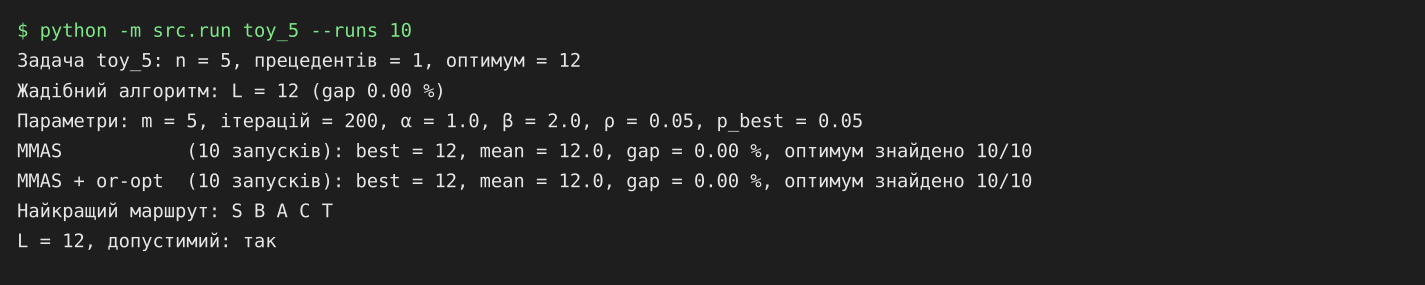

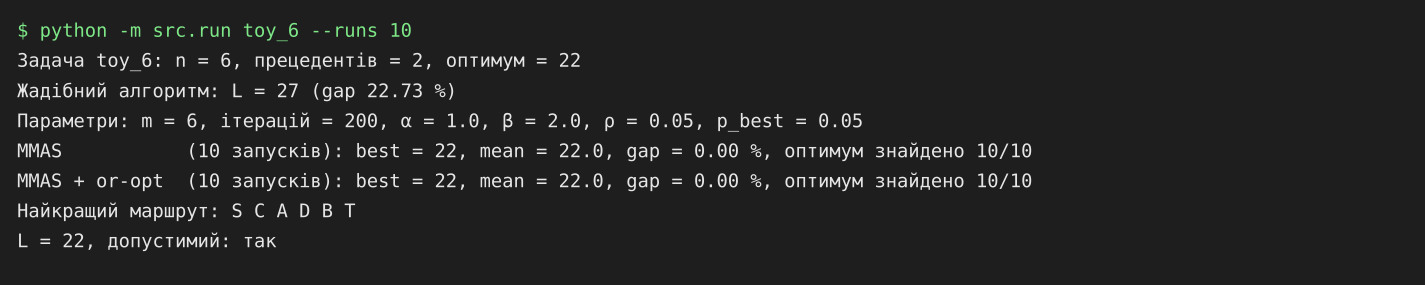

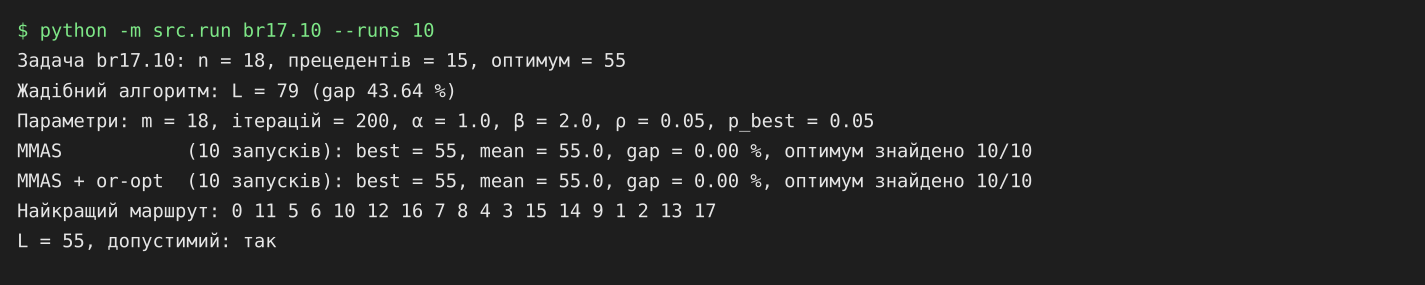

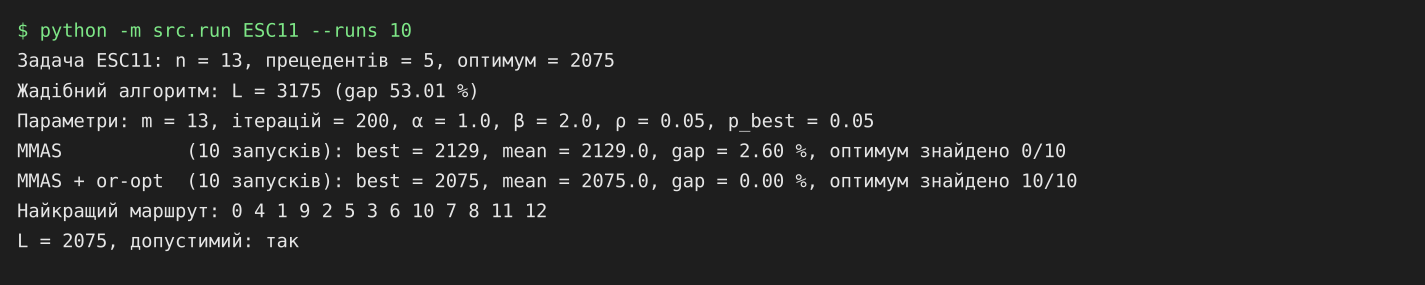

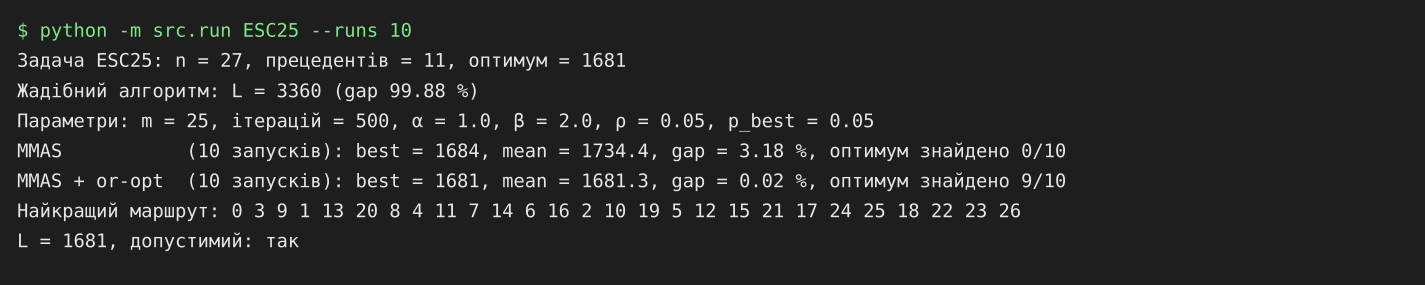

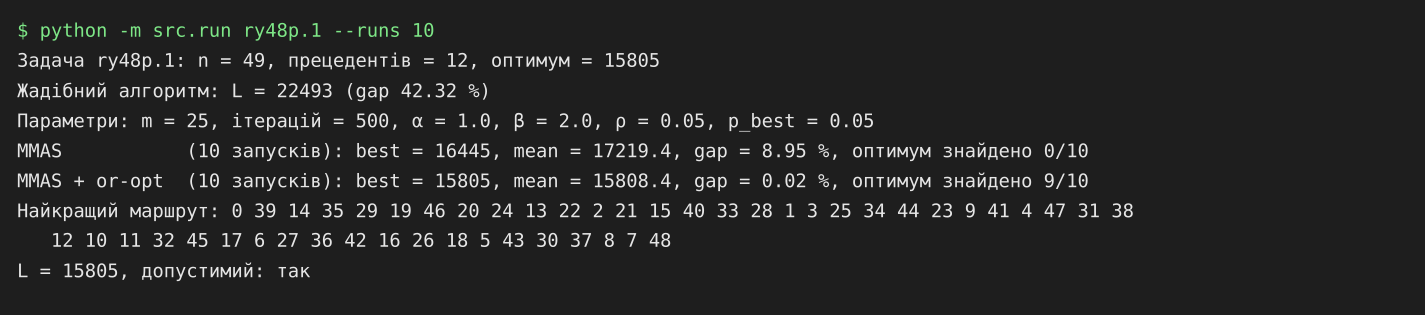

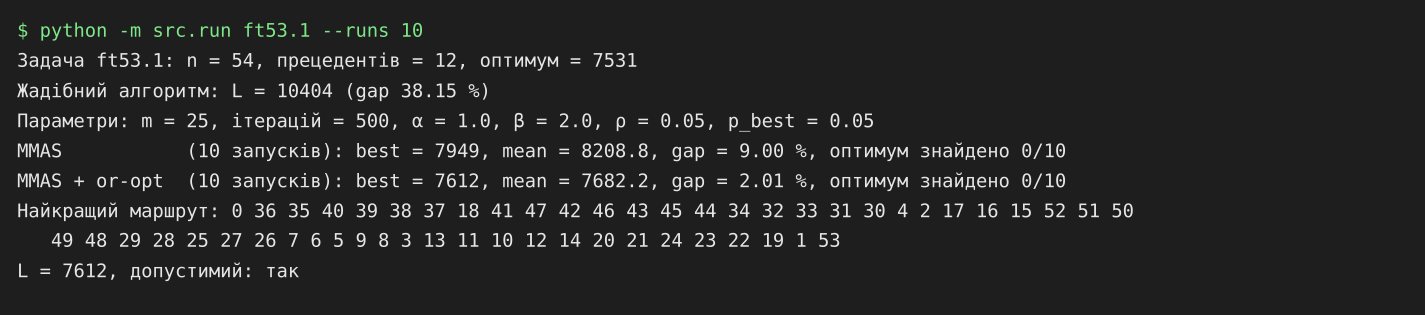

In [7]:
for name in REPORT_SET:
    display(Image(filename=f'{FIG}/run_{name}.png'))

## 4. Підбір параметрів (ESC25, 300 ітерацій, 10 запусків, без локального пошуку)

In [8]:
pd.read_csv(f'{TAB}/params_ESC25.csv', keep_default_na=False)

,param,value,best,mean,gap,time_s
0,alpha,0.5,1747.0,1811.3,7.75,2.40
1,alpha,1,1684.0,1734.4,3.18,2.38
2,alpha,2,1684.0,1817.9,8.14,2.38
3,alpha,3,1747.0,1817.1,8.10,2.42
4,beta,0,2434.0,2834.3,68.61,2.36
5,beta,1,1684.0,1746.9,3.92,2.37
6,beta,2,1684.0,1734.4,3.18,2.43
7,beta,3,1684.0,1799.0,7.02,2.39
8,beta,5,1886.0,1993.1,18.57,2.38
9,rho,0.01,1747.0,1953.5,16.21,2.42


## 5. Візуалізація (приклад 2)

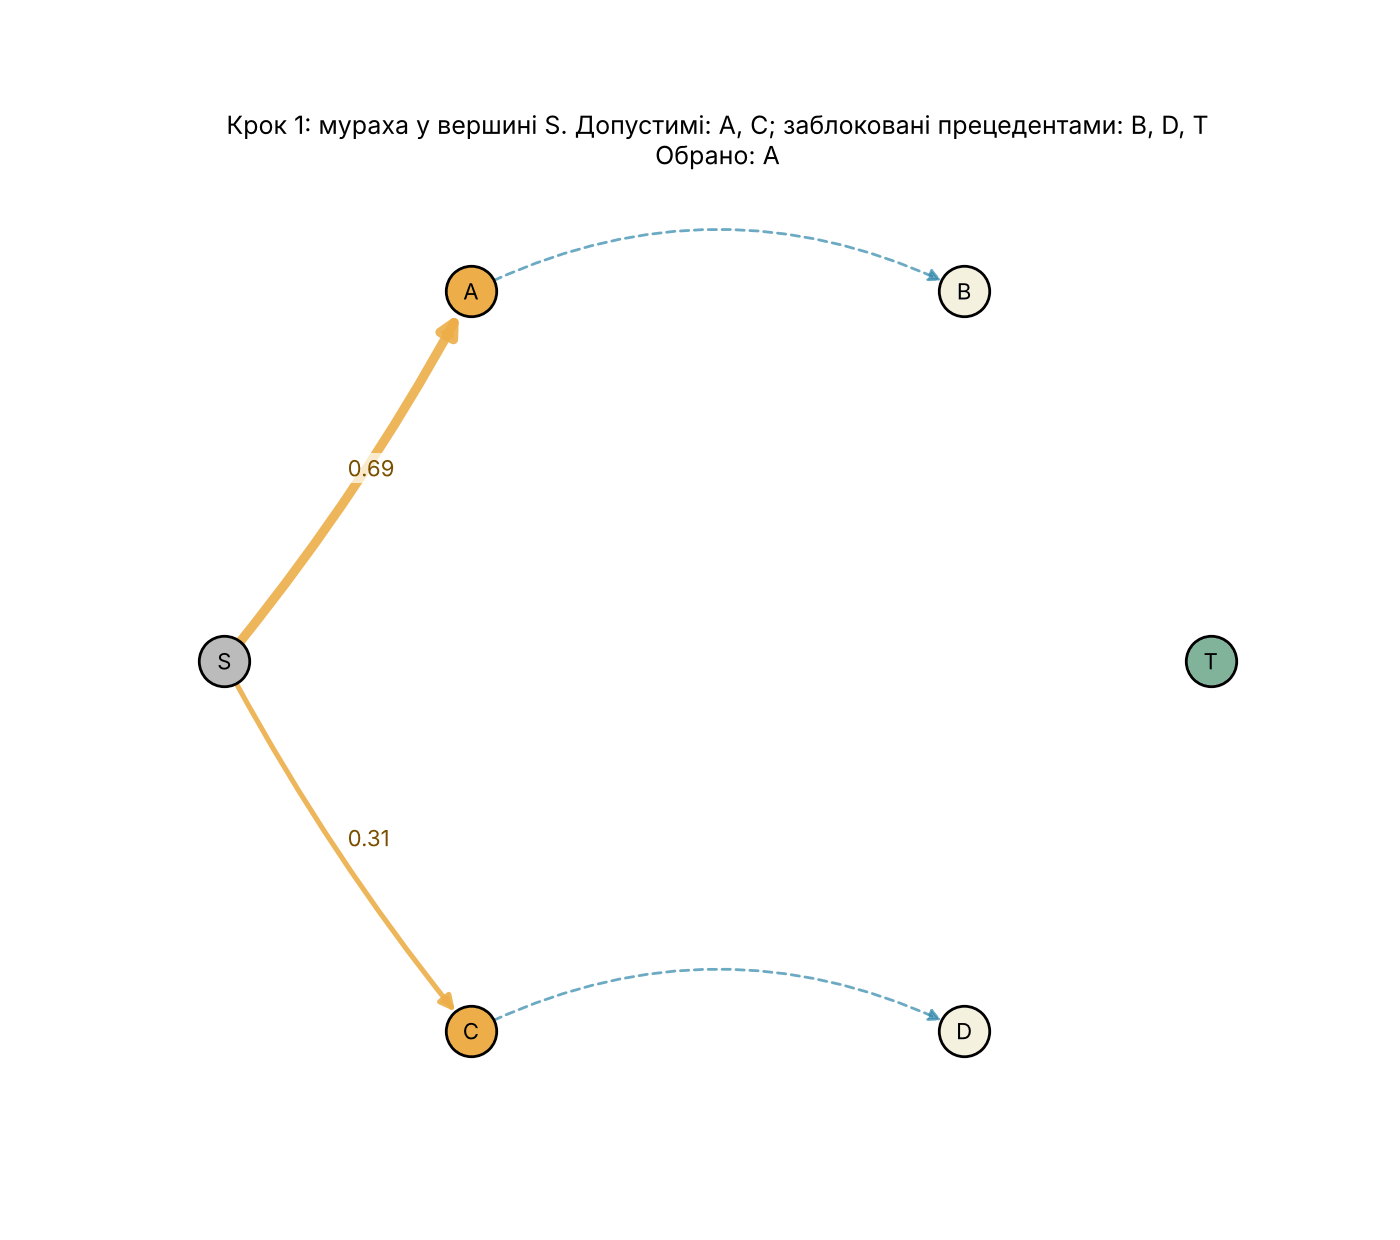

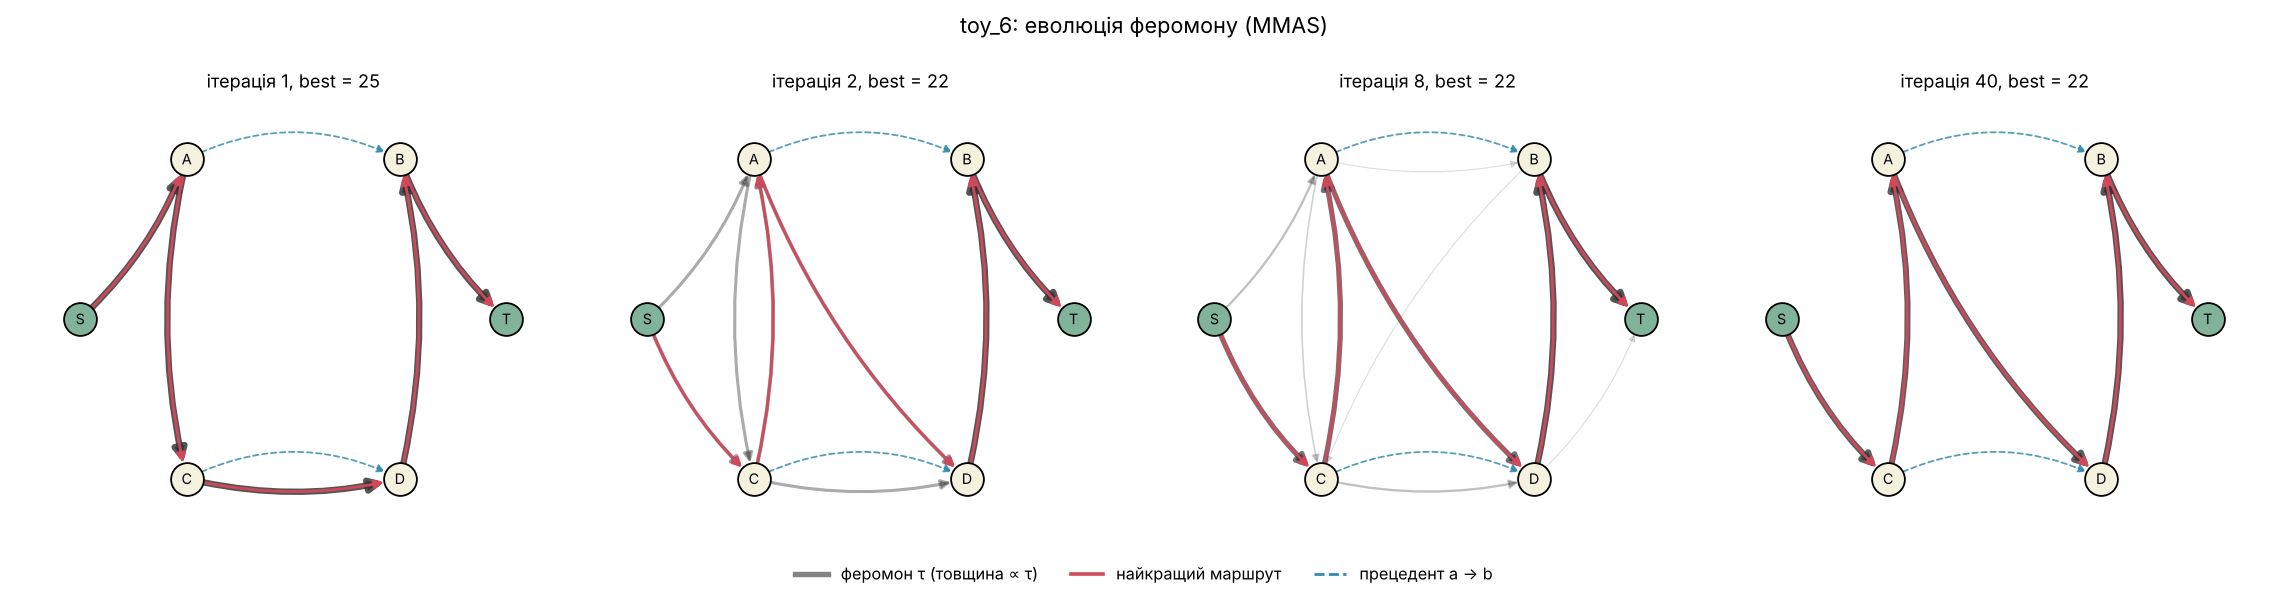

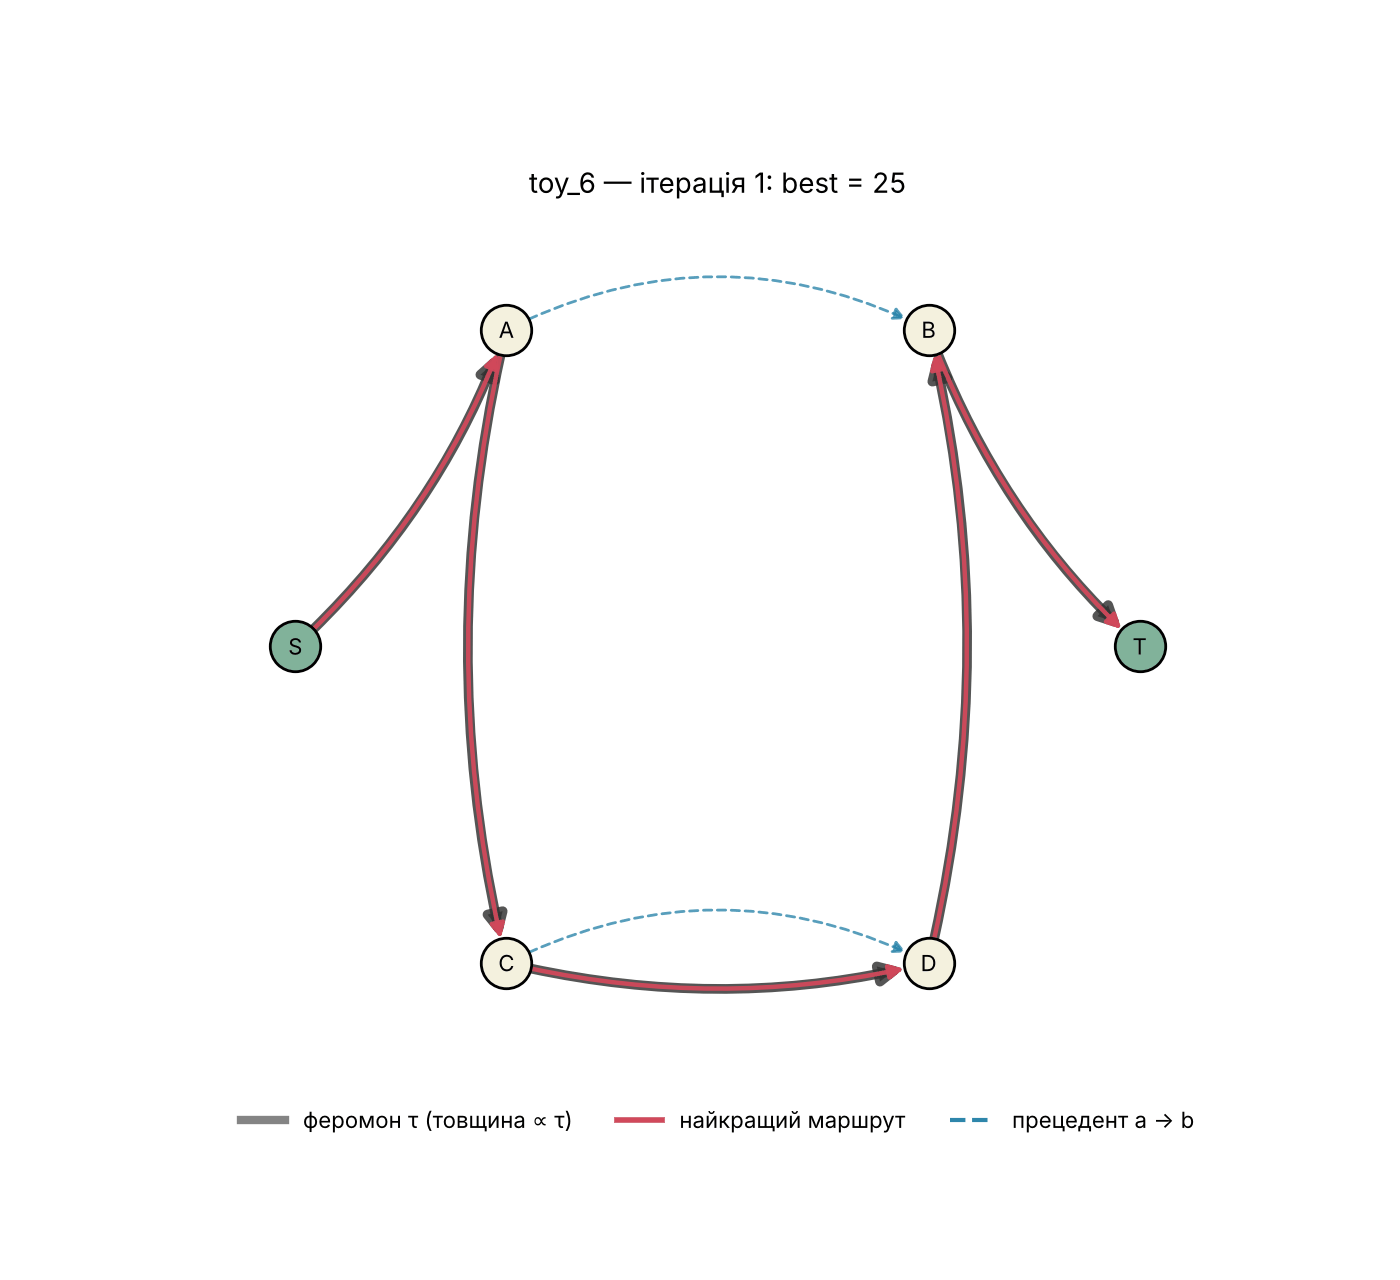

In [9]:
display(Image(filename=f'{GIF}/toy6_construction.gif'))
display(Image(filename=f'{FIG}/toy6_pheromone_sequence.png'))
display(Image(filename=f'{GIF}/toy6_pheromone.gif'))